# Лабораторная работа 1. Предсказание RiskScore

Выполнил Колосов Егор Евгеньевич, группа М8О-312БВ-24

Нужно предсказать `RiskScore` по данным о заёмщиках. Основная метрика — MSE.
Из моделей разрешена только линейная регрессия. `sklearn` используется для проверки собственных реализаций.

Целевой результат в соревновании — **MSE < 18**.

Исходные файлы `train.csv`, `test.csv` и `ex.csv` находятся в папке `data`.
Для запуска нужно выполнить ячейки по порядку. Путь к данным задаётся в `DATA_DIR`.
В конце создаётся `submission.csv`.

In [1]:
from pathlib import Path
import sys
import platform
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.linear_model import LinearRegression, SGDRegressor, Ridge, Lasso, ElasticNet
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import (mean_squared_error, mean_absolute_error,
                             r2_score, mean_absolute_percentage_error)
from sklearn.model_selection import KFold, LeaveOneOut
from threadpoolctl import threadpool_limits
from IPython.display import display, Markdown

# Ограничение действует только в текущем процессе: устойчивое время матричных операций.
thread_limit = threadpool_limits(limits=1)
SEED = 2026
DATA_DIR = Path('data')
OUTPUT_DIR = Path('.')
plt.rcParams.update({'figure.figsize': (10, 4), 'font.size': 10,
                     'axes.grid': True, 'grid.alpha': 0.2})
pd.set_option('display.max_columns', 12)
pd.set_option('display.precision', 6)
display(pd.Series({'Python': platform.python_version(), 'NumPy': np.__version__,
                   'pandas': pd.__version__, 'scikit-learn': sklearn.__version__,
                   'matplotlib': matplotlib.__version__}, name='Фактические версии'))

Python          3.13.15
NumPy             2.5.4
pandas            3.1.1
scikit-learn      1.9.1
matplotlib       3.11.2
Name: Фактические версии, dtype: str

## 1. Загрузка и проверка данных

Проверяю размеры таблиц, типы столбцов, пропуски и дубликаты.
В `train.csv` находится целевая переменная `RiskScore`, а в `test.csv` — идентификаторы `ID`.
Файл `ex.csv` задаёт формат посылки. Значения риска из него при обучении не используются.

In [2]:
paths = {name: DATA_DIR / f'{name}.csv' for name in ['train', 'test', 'ex']}
missing_files = [str(path) for path in paths.values() if not path.is_file()]
if missing_files:
    raise FileNotFoundError(f'Нужны исходные файлы: {missing_files}')
raw = pd.read_csv(paths['train'])
test = pd.read_csv(paths['test'])
example = pd.read_csv(paths['ex'])
assert 'RiskScore' in raw and 'ID' not in raw
assert 'RiskScore' not in test and 'ID' in test
feature_columns = raw.columns.drop('RiskScore').tolist()
assert test.columns.drop('ID').tolist() == feature_columns
assert example.columns.tolist() == ['ID', 'RiskScore']
assert test['ID'].notna().all() and test['ID'].is_unique
assert example['ID'].equals(test['ID'])
assert len(test) == len(example)
display(pd.DataFrame({'rows': [len(raw), len(test), len(example)],
                      'columns': [raw.shape[1], test.shape[1], example.shape[1]]},
                     index=['train', 'test', 'ex']))
schema = pd.DataFrame({'train_type': raw.dtypes.astype(str),
                      'missing_train': raw.isna().sum(),
                      'test_type': test.dtypes.astype(str),
                      'missing_test': test.isna().sum()})
display(schema)
display(raw.head(3))
display(raw.describe().T)
print('Полностью пустые строки:', raw.isna().all(axis=1).sum())
nonempty = raw.dropna(how='all')
print('Точные повторы среди непустых:', nonempty.duplicated().sum())
display(nonempty.loc[nonempty.RiskScore.abs() > 1e6, 'RiskScore'].value_counts())

,rows,columns
train,11017,35
test,5000,35
ex,5000,2


,train_type,missing_train,test_type,missing_test
Age,float64,530.0,int64,0.0
AnnualIncome,float64,530.0,int64,0.0
ApplicationDate,str,530.0,str,0.0
BankruptcyHistory,float64,1031.0,int64,0.0
BaseInterestRate,float64,1031.0,float64,0.0
CheckingAccountBalance,float64,1031.0,int64,0.0
CreditCardUtilizationRate,float64,530.0,float64,0.0
CreditScore,float64,1031.0,int64,0.0
DebtToIncomeRatio,float64,530.0,float64,0.0
EducationLevel,str,530.0,str,0.0


,ApplicationDate,Age,AnnualIncome,CreditScore,LoanAmount,LoanDuration,...,NetWorth,BaseInterestRate,InterestRate,MonthlyLoanPayment,TotalDebtToIncomeRatio,RiskScore
0,2010-06-26,27.0,66829.0,549.0,17290.0,60.0,...,35067.0,0.257790,0.251465,508.970230,0.288013,66.176500
1,1996-09-23,55.0,172147.0,850.0,16110.0,36.0,...,27001.0,0.086110,0.093173,514.675859,0.050585,28.495737
2,2015-01-19,51.0,300000.0,850.0,38436.0,36.0,...,278382.0,0.108436,0.115443,1268.276385,0.072571,34.488104


,count,mean,std,min,25%,50%,75%,max
Age,10487.0,39.850386,1.161413e+01,1.800000e+01,32.000000,40.000000,48.000000,8.000000e+01
AnnualIncome,10487.0,131587.872127,1.157919e+05,1.500000e+04,20959.500000,89015.000000,257025.000000,7.485080e+05
CreditScore,9986.0,678.082716,1.751925e+02,3.000000e+02,550.000000,722.500000,850.000000,8.500000e+02
LoanAmount,9986.0,29874.218306,2.770551e+04,1.063000e+03,12658.000000,21828.500000,37158.000000,4.189970e+05
LoanDuration,10487.0,53.439878,2.449356e+01,1.200000e+01,36.000000,48.000000,60.000000,1.200000e+02
NumberOfDependents,10487.0,1.568323,1.418684e+00,0.000000e+00,0.000000,1.000000,3.000000,6.000000e+00
MonthlyDebtPayments,9986.0,546.458642,5.019819e+02,1.300000e+01,233.250000,398.000000,685.000000,1.087900e+04
CreditCardUtilizationRate,10487.0,0.284397,1.592405e-01,3.673558e-03,0.158929,0.262229,0.391683,9.146347e-01
NumberOfOpenCreditLines,10487.0,3.033565,1.740186e+00,0.000000e+00,2.000000,3.000000,4.000000,1.200000e+01
NumberOfCreditInquiries,10487.0,0.979498,9.909274e-01,0.000000e+00,0.000000,1.000000,2.000000,6.000000e+00


Полностью пустые строки: 530
Точные повторы среди непустых: 487


RiskScore
-9999999.0     121
 10000000.0     94
Name: count, dtype: int64

### Очистка данных

- Удалены 530 полностью пустых строк.
- Удалены 487 точных дубликатов, чтобы одинаковые записи не попадали одновременно в обучение и проверку.
- Удалены значения цели `−9999999` и `10000000`. Они многократно повторяются и отличаются от остальных значений на несколько порядков, поэтому считаю их заглушками.
- Остальные значения цели и крайние значения признаков сохранены.

После очистки осталось 9 788 строк. Из них 7 830 использую для подбора модели (`development`),
а 1 958 оставляю для итоговой проверки (`holdout`). Медианы, категории и параметры нормализации
вычисляются только по обучающей части каждого разбиения.

In [3]:
without_missing_target = raw.dropna(subset=['RiskScore']).copy()
deduplicated = without_missing_target.drop_duplicates().copy()
sentinels = [-9999999.0, 10000000.0]
clean = deduplicated.loc[~deduplicated.RiskScore.isin(sentinels)].reset_index(drop=True)
assert np.isfinite(clean.RiskScore).all()
assert not clean[feature_columns].duplicated().any(), 'Нужен разбор повторов с разными целями'
cleaning_table = pd.DataFrame({
    'Этап': ['Исходные строки', 'Есть цель', 'Без точных повторов', 'Без двух заглушек'],
    'Строк': [len(raw), len(without_missing_target), len(deduplicated), len(clean)]})
display(cleaning_table)
order = np.random.default_rng(SEED).permutation(len(clean))
n_holdout = int(np.ceil(0.20 * len(clean)))
holdout_indices, dev_indices = order[:n_holdout], order[n_holdout:]
development = clean.iloc[dev_indices].reset_index(drop=True)
# До финальной проверки holdout нигде не участвует в подборе и графиках зависимостей.
print(f'development={len(development)}, holdout={len(holdout_indices)}')
assert set(dev_indices).isdisjoint(holdout_indices)
assert len(dev_indices) + len(holdout_indices) == len(clean)

,Этап,Строк
0,Исходные строки,11017
1,Есть цель,10487
2,Без точных повторов,10000
3,Без двух заглушек,9788


development=7830, holdout=1958


## 2. Разведочный анализ данных (EDA)

EDA проводится на выборке для подбора модели. Рассматриваю распределение цели,
связи финансовых показателей и матрицу корреляций.

,count,mean,std,min,25%,50%,75%,max
Age,7830.0,39.885951,11.532597,18.000000,32.000000,40.000000,48.000000,8.000000e+01
AnnualIncome,7830.0,132299.597957,116004.474474,15000.000000,22140.750000,90997.000000,257741.500000,7.485080e+05
CreditScore,7468.0,679.361409,175.036376,300.000000,553.000000,724.000000,850.000000,8.500000e+02
LoanAmount,7468.0,29903.004954,27562.186573,1063.000000,12639.500000,22011.000000,37310.250000,4.189970e+05
LoanDuration,7830.0,53.405364,24.553188,12.000000,36.000000,48.000000,60.000000,1.200000e+02
NumberOfDependents,7830.0,1.560026,1.420130,0.000000,0.000000,1.000000,3.000000,6.000000e+00
MonthlyDebtPayments,7468.0,549.146760,514.211369,13.000000,235.000000,399.000000,685.000000,1.087900e+04
CreditCardUtilizationRate,7830.0,0.284505,0.158741,0.003674,0.159627,0.263511,0.391093,9.146347e-01
NumberOfOpenCreditLines,7830.0,3.026820,1.732839,0.000000,2.000000,3.000000,4.000000,1.200000e+01
NumberOfCreditInquiries,7830.0,0.978416,0.994258,0.000000,0.000000,1.000000,2.000000,6.000000e+00


,missing,unique
MonthlyDebtPayments,362,1606
LoanAmount,362,6958
CreditScore,362,547
BaseInterestRate,362,7380
NetWorth,362,7045
TotalAssets,362,7296
BankruptcyHistory,362,2
LoanPurpose,362,5
CheckingAccountBalance,362,3520
ApplicationDate,0,7830


MaritalStatus,Married,Single,Divorced,Widowed
MaritalStatus,3833,2425,1158,414


HomeOwnershipStatus,Mortgage,Rent,Own,Other
HomeOwnershipStatus,3094,2367,1603,766


LoanPurpose,Home,Debt Consolidation,Auto,Education,Other,__missing__
LoanPurpose,2226,1810,1541,1193,698,362


EmploymentStatus,Employed,Self-Employed,Unemployed
EmploymentStatus,6782,728,320


EducationLevel,High School,Bachelor,Associate,Master,Doctorate
EducationLevel,3180,2275,1547,566,262


Дата: от 1979-01-01 до 2020-01-25 ; нераспознано: 0


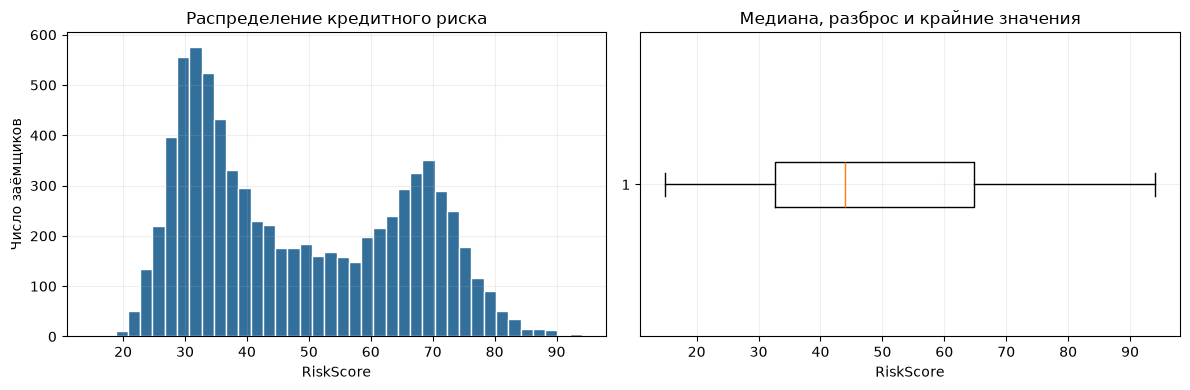

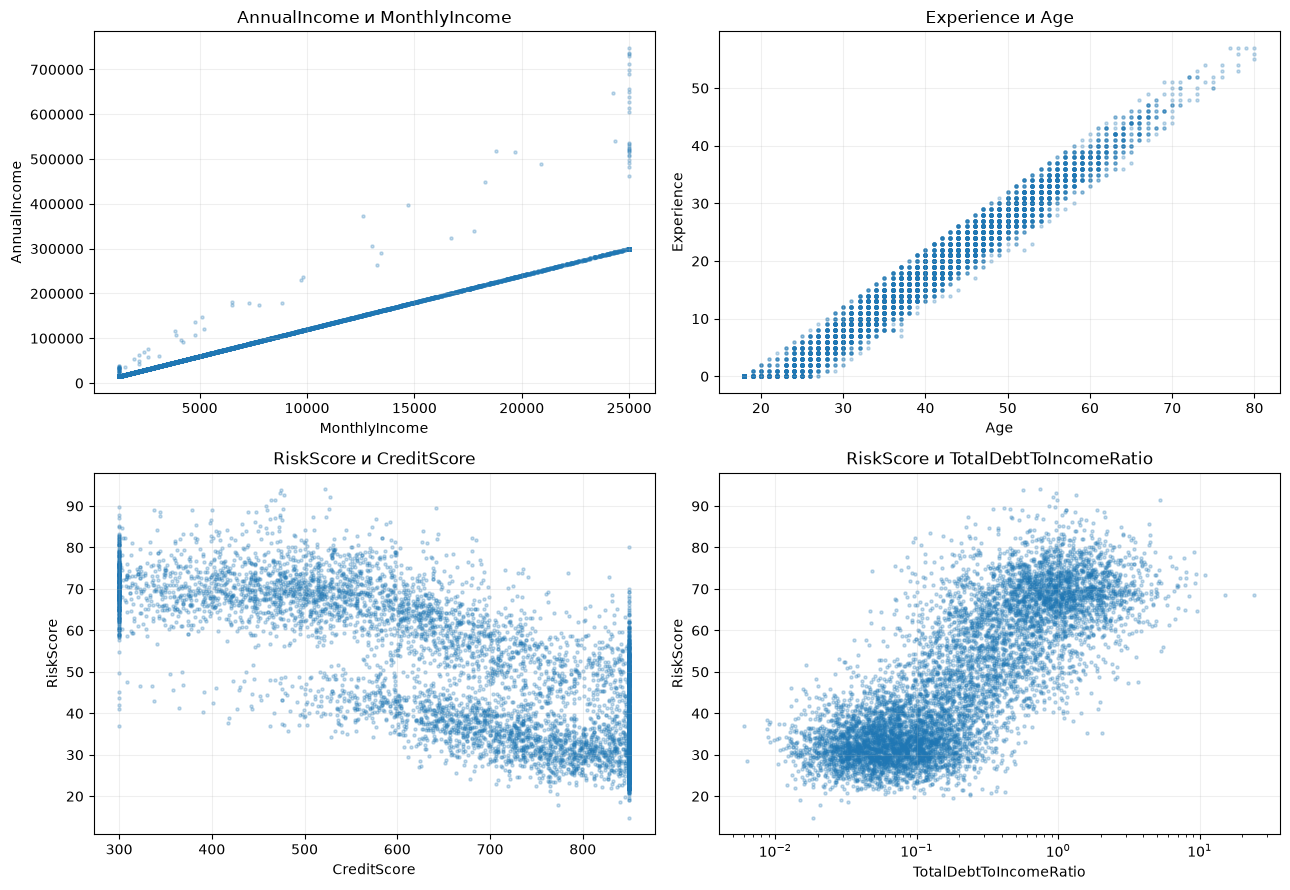

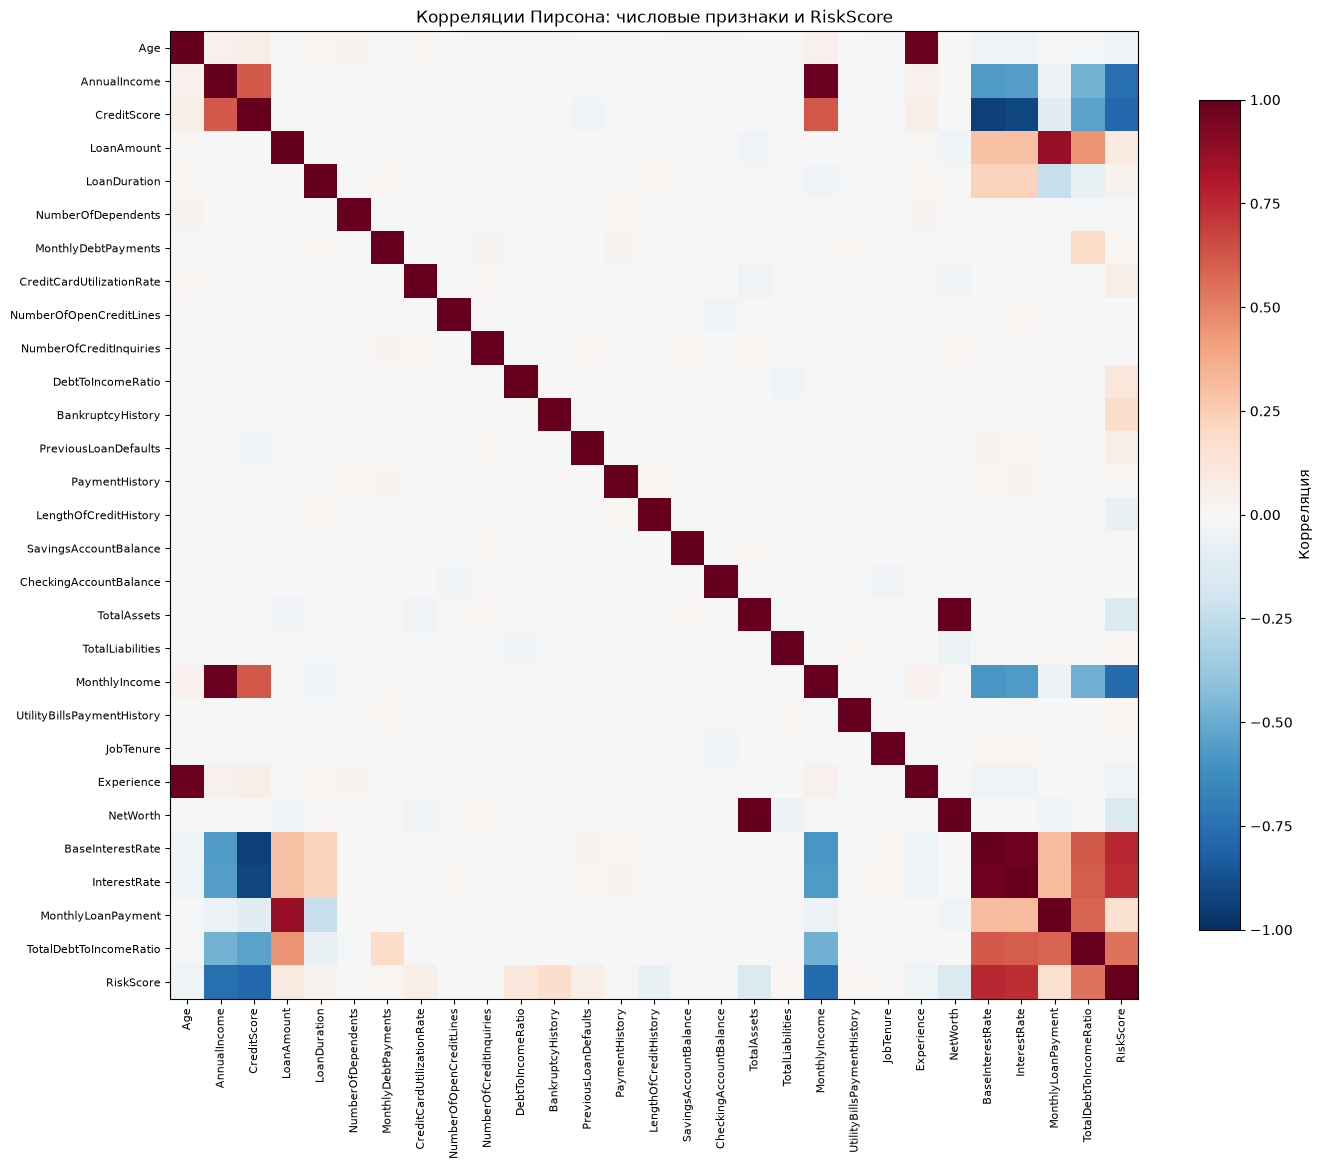

,RiskScore
CreditScore,-0.781911
MonthlyIncome,-0.768210
BaseInterestRate,0.755910
AnnualIncome,-0.755440
InterestRate,0.740639
TotalDebtToIncomeRatio,0.541832
BankruptcyHistory,0.174735
MonthlyLoanPayment,0.154815
TotalAssets,-0.143839
NetWorth,-0.141755


In [4]:
display(development.describe().T)
display(pd.DataFrame({'missing': development.isna().sum(),
                      'unique': development.nunique()}).sort_values('missing', ascending=False))
categorical_columns = [c for c in feature_columns
                       if not pd.api.types.is_numeric_dtype(development[c]) and c != 'ApplicationDate']
for col in categorical_columns:
    display(development[col].fillna('__missing__').value_counts().rename(col).to_frame().T)
dates = pd.to_datetime(development.ApplicationDate, errors='coerce')
print('Дата: от', dates.min().date(), 'до', dates.max().date(), '; нераспознано:', dates.isna().sum())
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(development.RiskScore, bins=40, color='#326f9b', edgecolor='white')
ax[0].set(xlabel='RiskScore', ylabel='Число заёмщиков', title='Распределение кредитного риска')
ax[1].boxplot(development.RiskScore, orientation='horizontal')
ax[1].set(xlabel='RiskScore', title='Медиана, разброс и крайние значения')
fig.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
plot_pairs = [('MonthlyIncome', 'AnnualIncome'), ('Age', 'Experience'),
              ('CreditScore', 'RiskScore'), ('TotalDebtToIncomeRatio', 'RiskScore')]
for ax, (a, b) in zip(axes.flat, plot_pairs):
    good = development[[a, b]].dropna()
    ax.scatter(good[a], good[b], s=5, alpha=0.25, rasterized=True)
    ax.set(xlabel=a, ylabel=b, title=f'{b} и {a}')
    if a == 'TotalDebtToIncomeRatio':
        ax.set_xscale('log')
fig.tight_layout(); plt.show()

corr = development.select_dtypes(include='number').corr()
fig, ax = plt.subplots(figsize=(14, 12))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr)), corr.index, fontsize=8)
ax.set_title('Корреляции Пирсона: числовые признаки и RiskScore')
ax.grid(False)
fig.colorbar(im, ax=ax, label='Корреляция', shrink=0.8)
fig.tight_layout(); plt.show()
display(corr.RiskScore.drop('RiskScore').sort_values(key=abs, ascending=False).head(10).to_frame())

### Выводы EDA

1. Распределение `RiskScore` имеет два выраженных пика, около 30 и 68. На графиках видны две группы наблюдений; одной прямой трудно описать такую зависимость.
2. Доход и кредитный рейтинг связаны с уменьшением риска, а долговая нагрузка — с его ростом.
3. Денежные показатели имеют разные масштабы и длинные правые хвосты. Поэтому дальше проверяю нормализацию и логарифмы.
4. Возраст и стаж, годовой и месячный доходы сильно связаны между собой. Такие зависимости могут приводить к неустойчивым коэффициентам.
5. Пропуски сосредоточены в одном наборе столбцов. Для них использую восстановление по финансовым формулам, а для оставшихся — медианы и индикаторы пропуска.
6. Полезность даты проверяю отдельно по кросс-валидации. `ID` нужен только для формирования посылки.

## 3. Метрики

Для ошибки $e_i=y_i-\hat y_i$:

$$\mathrm{MSE}=\frac1n\sum e_i^2,\qquad
\mathrm{MAE}=\frac1n\sum |e_i|,$$
$$R^2=1-\frac{\sum e_i^2}{\sum(y_i-\bar y)^2},\qquad
\mathrm{MAPE}=\frac1n\sum\frac{|e_i|}{\max(|y_i|,\varepsilon)}.$$

MAPE возвращается долей, для перевода в проценты результат умножается на 100.
В знаменателе используется машинная точность `float64`, как в `sklearn`.
При нулевых и близких к нулю значениях цели MAPE становится очень большой.

Для постоянной цели R² равен 1 при точном прогнозе и 0 в остальных случаях.
Для одного наблюдения R² не определён и возвращается `NaN`.
Ниже проверяю метрики на небольшом примере и сравниваю со `sklearn`.

In [5]:
def _vectors(y_true, y_pred):
    a, b = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    if a.ndim != 1 or b.ndim != 1 or a.shape != b.shape or len(a) == 0:
        raise ValueError("Ожидаются непустые одномерные векторы одинаковой длины")
    if not (np.isfinite(a).all() and np.isfinite(b).all()):
        raise ValueError("В метриках недопустимы NaN и бесконечности")
    return a, b

def mse(y_true, y_pred):
    a, b = _vectors(y_true, y_pred)
    return float(np.mean((a - b) ** 2))

def mae(y_true, y_pred):
    a, b = _vectors(y_true, y_pred)
    return float(np.mean(np.abs(a - b)))

def r2(y_true, y_pred):
    """Поведение соответствует sklearn r2_score(force_finite=True)."""
    a, b = _vectors(y_true, y_pred)
    if len(a) < 2:
        return float("nan")
    numerator = np.sum((a - b) ** 2)
    denominator = np.sum((a - a.mean()) ** 2)
    if denominator == 0:
        return 1.0 if numerator == 0 else 0.0
    return float(1 - numerator / denominator)

def mape(y_true, y_pred):
    """Возвращает долю; знаменатель max(|y|, eps float64), как в sklearn."""
    a, b = _vectors(y_true, y_pred)
    return float(np.mean(np.abs(a - b) / np.maximum(np.abs(a), np.finfo(float).eps)))

def metrics(y_true, y_pred):
    return {"MSE": mse(y_true, y_pred), "MAE": mae(y_true, y_pred),
            "R2": r2(y_true, y_pred), "MAPE": mape(y_true, y_pred)}

In [6]:
yt, yp = np.array([1., 2., 4.]), np.array([1., 3., 2.])
expected = {'MSE': 5/3, 'MAE': 1., 'R2': -1/14, 'MAPE': 1/3}
references = {'MSE': mean_squared_error, 'MAE': mean_absolute_error,
              'R2': r2_score, 'MAPE': mean_absolute_percentage_error}
metric_checks = []
for key, value in metrics(yt, yp).items():
    reference = references[key](yt, yp)
    assert np.isclose(value, expected[key]) and np.isclose(value, reference)
    metric_checks.append([key, expected[key], value, reference])
display(pd.DataFrame(metric_checks, columns=['Метрика', 'Ожидается', 'Своя', 'sklearn']))
for a, b in [([2.,2.], [2.,2.]), ([2.,2.], [1.,3.]),
             ([0.,1e-20,2.], [1.,1.,1.])]:
    for key, value in metrics(a, b).items():
        assert np.isclose(value, references[key](a,b), rtol=1e-14)
with warnings.catch_warnings(record=True) as expected_warnings:
    reference_single = r2_score([1.], [1.])
assert np.isnan(r2([1.],[1.])) and np.isnan(reference_single)
print('MAPE для нулевой/почти нулевой цели:', mape([0.,1e-20,2.],[1.,1.,1.]))
print('Проверки четырёх метрик и особых случаев пройдены.')

,Метрика,Ожидается,Своя,sklearn
0,MSE,1.666667,1.666667,1.666667
1,MAE,1.000000,1.000000,1.000000
2,R2,-0.071429,-0.071429,-0.071429
3,MAPE,0.333333,0.333333,0.333333


MAPE для нулевой/почти нулевой цели: 3002399751580330.5
Проверки четырёх метрик и особых случаев пройдены.


## 4. Нормализация

$$z_j=\frac{x_j-\mu_j}{\sigma_j},\qquad
\sigma_j=\sqrt{\frac1n\sum_i(x_{ij}-\mu_j)^2},\qquad
u_j=\frac{x_j-\min_j}{\max_j-\min_j}.$$

В `fit` сохраняются параметры обучающей части, в `transform` они применяются к новым данным.
Стандартное отклонение считается с `ddof=0`, как у `StandardScaler`.
Для константного столбца знаменатель заменяется единицей.
После min-max значения на проверке могут выходить за [0, 1], если выходят за диапазон обучения.

In [7]:
def _matrix(X):
    a = np.asarray(X, dtype=float)
    if a.ndim != 2 or a.shape[0] == 0 or a.shape[1] == 0:
        raise ValueError("X должна быть непустой двумерной матрицей")
    if not np.isfinite(a).all():
        raise ValueError("Сначала заполните пропуски и обработайте бесконечности")
    return a

class Scaler:
    """fit обучает параметры; transform использует их без переобучения."""
    def __init__(self, method="zscore"):
        if method not in ("zscore", "minmax"):
            raise ValueError("method: zscore или minmax")
        self.method = method

    def fit(self, X):
        X = _matrix(X)
        self.n_features_in_ = X.shape[1]
        if self.method == "zscore":
            self.location_ = X.mean(axis=0)
            self.scale_ = X.std(axis=0, ddof=0)
        else:
            self.location_ = X.min(axis=0)
            self.scale_ = X.max(axis=0) - self.location_
        self.constant_ = self.scale_ == 0
        self.scale_[self.constant_] = 1.0
        return self

    def transform(self, X):
        if not hasattr(self, "scale_"):
            raise RuntimeError("Сначала вызовите fit")
        X = _matrix(X)
        if X.shape[1] != self.n_features_in_:
            raise ValueError("Количество признаков изменилось")
        return (X - self.location_) / self.scale_

    def fit_transform(self, X):
        return self.fit(X).transform(X)

In [8]:
def kfold_splits(n_samples, k=5, shuffle=True, random_state=42):
    """Каждая строка входит в validation один раз, размеры отличаются <= 1."""
    if (not isinstance(n_samples, (int, np.integer)) or not isinstance(k, (int, np.integer))
            or not 2 <= k <= n_samples):
        raise ValueError("Нужно целое 2 <= k <= n_samples")
    indices = np.arange(n_samples)
    if shuffle:
        indices = np.random.default_rng(random_state).permutation(indices)
    folds = np.array_split(indices, k)
    for i in range(k):
        yield np.concatenate([folds[j] for j in range(k) if j != i]), folds[i].copy()

def loo_splits(n_samples):
    """Честный LOO: n_samples разбиений, один исключённый объект в каждом."""
    if not isinstance(n_samples, (int, np.integer)) or n_samples < 2:
        raise ValueError("LOO требует как минимум два наблюдения")
    indices = np.arange(n_samples)
    for i in range(n_samples):
        yield np.concatenate((indices[:i], indices[i + 1:])), indices[i:i + 1].copy()

In [9]:
cv_splits = list(kfold_splits(len(development), k=3, random_state=42))
train_idx, val_idx = cv_splits[0]
solver_columns = ['Age', 'MonthlyIncome', 'DebtToIncomeRatio', 'CreditCardUtilizationRate',
                  'PreviousLoanDefaults', 'PaymentHistory', 'LengthOfCreditHistory',
                  'UtilityBillsPaymentHistory']
solver_train = development.iloc[train_idx][solver_columns].to_numpy(float)
solver_val = development.iloc[val_idx][solver_columns].to_numpy(float)
normalization_results = []
for method, reference_class in [('zscore',StandardScaler), ('minmax',MinMaxScaler)]:
    own = Scaler(method).fit(solver_train)
    reference = reference_class().fit(solver_train)
    for split_name, a in [('train',solver_train),('validation',solver_val)]:
        difference = np.max(np.abs(own.transform(a)-reference.transform(a)))
        assert np.allclose(own.transform(a), reference.transform(a), atol=1e-12)
        normalization_results.append([method,split_name,difference])
    constant_train = np.column_stack([solver_train, np.full(len(solver_train), 7.)])
    constant_val = np.column_stack([solver_val, np.full(len(solver_val), 7.)])
    assert np.allclose(Scaler(method).fit(constant_train).transform(constant_val),
                       reference_class().fit(constant_train).transform(constant_val))
display(pd.DataFrame(normalization_results,columns=['Способ','Часть','max |разница|']))
display(pd.DataFrame({'MonthlyIncome':solver_val[:6,1],
                      'zscore':Scaler().fit(solver_train).transform(solver_val)[:6,1],
                      'minmax':Scaler('minmax').fit(solver_train).transform(solver_val)[:6,1]}))

,Способ,Часть,max |разница|
0,zscore,train,0.000000e+00
1,zscore,validation,0.000000e+00
2,minmax,train,2.220446e-16
3,minmax,validation,2.220446e-16


,MonthlyIncome,zscore,minmax
0,25000.00,1.512447,1.000000
1,14900.25,0.435623,0.574747
2,15268.00,0.474832,0.590232
3,25000.00,1.512447,1.000000
4,1250.00,-1.019751,0.000000
5,1250.00,-1.019751,0.000000


## 5. Класс линейной регрессии

Модель $\hat y=b+Xw$ минимизирует функцию
$$J(w,b)=\frac1{2n}\|Xw+b-y\|_2^2.$$

Реализованы три способа обучения:

- **Аналитический.** Для матрицы $\widetilde X$ с единичным столбцом решение при полном ранге имеет вид $\theta=(\widetilde X^T\widetilde X)^{-1}\widetilde X^Ty$. В коде данные центрируются, а минимум находится через `np.linalg.lstsq`. Это позволяет обойтись без обращения матрицы и работать с зависимыми столбцами.
- **GD.** Градиент считается по всей выборке: $\nabla_wJ=X^T(Xw+b-y)/n$. Шаг по умолчанию равен $1/L$, где $L$ — максимальное собственное значение $X_c^TX_c/n$.
- **SGD.** Веса обновляются по одному наблюдению. Для ошибки $d_i=\hat y_i-y_i$ обновления имеют вид $w\leftarrow w-\eta_t d_ix_i$, $b\leftarrow b-\eta_t d_i$. Шаг уменьшается по формуле $\eta_t=\eta_0/t^q$. Между эпохами наблюдения перемешиваются с фиксированным `random_state`.

Свободный член поддерживается во всех методах. Для SGD также предусмотрено усреднение весов.
История обучения хранит MSE. Слишком большой шаг GD и нечисловые значения проверяются в классе.

In [10]:
class LinearRegressionOwn:
    """OLS: analytical, full batch GD или SGD по одному наблюдению.

    Минимизируется SSE/(2n), поэтому градиент равен X.T @ (Xw-y)/n.
    history_ хранит MSE без штрафов. learning_rate=None выбирает безопасный
    шаг GD по спектру Gram; для SGD выбирается консервативный шаг по нормам
    строк. SGD: eta_t = eta_0 / t**power_t. average=True усредняет обновления.
    Центрирование внутри fit эквивалентно добавлению свободного члена.
    """
    def __init__(self, method="analytical", fit_intercept=True, learning_rate=None,
                 max_epochs=5000, tol=1e-9, random_state=42, power_t=0.25,
                 average=False, patience=15):
        self.method = method
        self.fit_intercept = fit_intercept
        self.learning_rate = learning_rate
        self.max_epochs = max_epochs
        self.tol = tol
        self.random_state = random_state
        self.power_t = power_t
        self.average = average
        self.patience = patience

    def fit(self, X, y):
        X = _matrix(X)
        y, _ = _vectors(y, y)
        if len(y) != len(X):
            raise ValueError("X и y имеют разное число наблюдений")
        if self.method not in ("analytical", "gd", "sgd"):
            raise ValueError("method: analytical, gd или sgd")
        if (not isinstance(self.max_epochs, (int, np.integer)) or self.max_epochs < 1
                or not np.isfinite(self.tol) or self.tol < 0
                or not 0 <= self.power_t <= 1 or self.patience < 1):
            raise ValueError("Проверьте max_epochs, tol, power_t и patience")
        if self.learning_rate is not None and (not np.isfinite(self.learning_rate)
                                              or self.learning_rate <= 0):
            raise ValueError("learning_rate должна быть положительной")
        self.n_features_in_ = X.shape[1]
        self.x_mean_ = X.mean(axis=0) if self.fit_intercept else np.zeros(X.shape[1])
        self.y_mean_ = y.mean() if self.fit_intercept else 0.0
        A, z = X - self.x_mean_, y - self.y_mean_
        w, bias = np.zeros(X.shape[1]), 0.0
        self.history_ = []
        self.converged_ = False
        if self.method == "analytical":
            w, _, self.rank_, self.singular_values_ = np.linalg.lstsq(A, z, rcond=None)
            self.n_iter_ = 1
            self.converged_ = True
            self.history_.append(mse(z, A @ w))
        elif self.method == "gd":
            G, rhs = A.T @ A / len(A), A.T @ z / len(A)
            top_eigenvalue = max(float(np.linalg.eigvalsh(G)[-1]), np.finfo(float).eps)
            self.learning_rate_ = (1.0 / top_eigenvalue if self.learning_rate is None
                                   else self.learning_rate)
            if self.learning_rate_ >= 2 / top_eigenvalue:
                raise ValueError("Шаг GD нарушает условие устойчивости eta < 2/L")
            initial = float(z @ z / len(z))
            gradient_scale = max(1.0, float(np.max(np.abs(rhs))))
            self.history_.append(initial)
            for epoch in range(self.max_epochs):
                gradient = G @ w - rhs
                w -= self.learning_rate_ * gradient
                loss = max(0.0, float(w @ G @ w - 2 * rhs @ w + initial))
                self._check_finite(w, loss, initial)
                self.history_.append(loss)
                if np.max(np.abs(G @ w - rhs)) <= self.tol * gradient_scale:
                    self.converged_ = True
                    break
            self.n_iter_ = epoch + 1
        else:
            rng = np.random.default_rng(self.random_state)
            row_norm = np.sum(A * A, axis=1) + int(self.fit_intercept)
            self.learning_rate_ = (0.5 / max(1.0, float(row_norm.max()))
                                   if self.learning_rate is None else self.learning_rate)
            self.history_.append(float(np.mean(z * z)))
            initial = self.history_[0]
            step, sum_w, sum_bias = 0, np.zeros_like(w), 0.0
            stale, previous = 0, initial
            for epoch in range(self.max_epochs):
                for i in rng.permutation(len(A)):
                    step += 1
                    eta = self.learning_rate_ / step ** self.power_t
                    error = A[i] @ w + bias - z[i]
                    w -= eta * error * A[i]
                    if self.fit_intercept:
                        bias -= eta * error
                    if self.average:
                        sum_w += w
                        sum_bias += bias
                estimate_w = sum_w / step if self.average else w
                estimate_bias = sum_bias / step if self.average else bias
                loss = mse(z, A @ estimate_w + estimate_bias)
                self._check_finite(estimate_w, loss, initial)
                self.history_.append(loss)
                stale = stale + 1 if abs(previous - loss) <= self.tol * max(1.0, previous) else 0
                if stale >= self.patience:
                    self.converged_ = True
                    break
                previous = loss
            if self.average:
                w, bias = sum_w / step, sum_bias / step
            self.n_iter_, self.n_updates_ = epoch + 1, step
        self.coef_ = w
        self.intercept_ = float(self.y_mean_ - self.x_mean_ @ w + bias)
        return self

    @staticmethod
    def _check_finite(w, loss, initial):
        if not np.isfinite(w).all() or not np.isfinite(loss) or loss > 1e12 * max(1, initial):
            raise FloatingPointError("Обучение расходится: уменьшите шаг или проверьте масштаб")

    def predict(self, X):
        if not hasattr(self, "coef_"):
            raise RuntimeError("Сначала вызовите fit")
        X = _matrix(X)
        if X.shape[1] != self.n_features_in_:
            raise ValueError("Количество признаков изменилось")
        prediction = X @ self.coef_ + self.intercept_
        if not np.isfinite(prediction).all():
            raise FloatingPointError("Получены нечисловые предсказания")
        return prediction

,Метод,MSE,b,w1,w2
0,analytical,9.860761e-32,3.0,2.0,-1.0
1,gd,7.685947e-21,3.0,2.0,-1.0
2,sgd,3.786532e-29,3.0,2.0,-1.0


,Вариант,MSE,MAE,R2,MAPE
0,own analytical,108.639793,8.390808,0.626829,0.196970
1,own GD,108.639793,8.390808,0.626829,0.196970
2,own SGD averaged,108.639987,8.390684,0.626829,0.196965
3,sklearn LinearRegression,108.639793,8.390808,0.626829,0.196970
4,sklearn SGDRegressor,108.639483,8.390709,0.626831,0.196966


GD эпох: 11 ; SGD эпох: 350 ; одиночных обновлений: 1827000
Max разница OLS/sklearn: 4.263256414560601e-14
Max разница GD/OLS: 2.561417744573191e-09


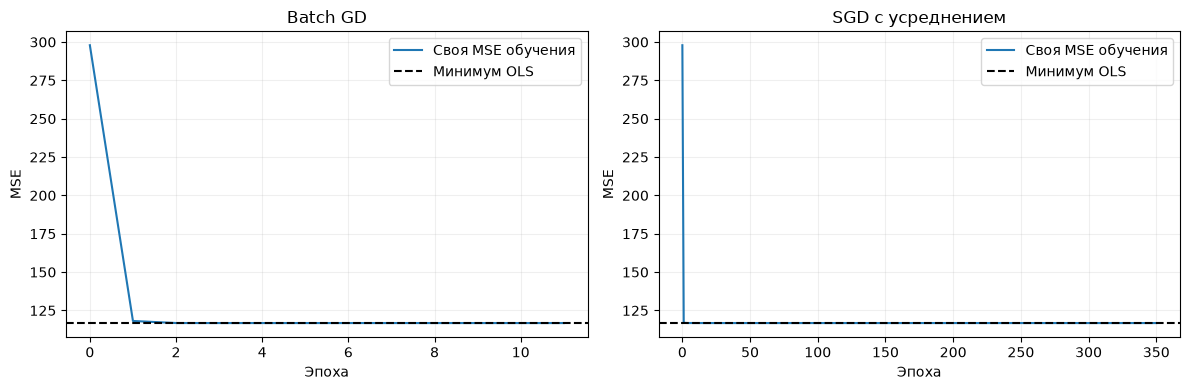

In [11]:
# Маленький пример с известными коэффициентами и свободным членом.
small_x = np.array([[0.,0.],[1.,0.],[0.,1.],[1.,1.],[2.,-1.],[-1.,2.]])
small_y = 3 + small_x @ np.array([2.,-1.])
small_results = []
for method, kwargs in [('analytical',{}), ('gd',{'max_epochs':10000,'tol':1e-11}),
                       ('sgd',{'learning_rate':0.05,'max_epochs':1800,
                               'tol':0.,'power_t':0.1,'random_state':42})]:
    fitted = LinearRegressionOwn(method,**kwargs).fit(small_x,small_y)
    error = mse(small_y,fitted.predict(small_x))
    assert error < 1e-7
    small_results.append([method,error,fitted.intercept_,*fitted.coef_])
display(pd.DataFrame(small_results,columns=['Метод','MSE','b','w1','w2']))

# Одинаковый фиксированный набор независимых по смыслу признаков для сравнения оптимизаторов.
solver_scaler = Scaler().fit(solver_train)
A_train, A_val = solver_scaler.transform(solver_train), solver_scaler.transform(solver_val)
y_train = development.iloc[train_idx].RiskScore.to_numpy()
y_val = development.iloc[val_idx].RiskScore.to_numpy()
ols = LinearRegressionOwn().fit(A_train,y_train)
gd = LinearRegressionOwn('gd',max_epochs=20000,tol=1e-10).fit(A_train,y_train)
sgd_settings = dict(learning_rate=0.015,max_epochs=350,tol=0.,random_state=42,
                    power_t=0.25,average=True)
sgd = LinearRegressionOwn('sgd',**sgd_settings).fit(A_train,y_train)
ols_ref = LinearRegression().fit(A_train,y_train)
# Центрирование y согласует начальный свободный член и средний уровень прогноза.
sgd_ref = SGDRegressor(loss='squared_error',penalty=None,fit_intercept=True,
                       learning_rate='invscaling',eta0=sgd.learning_rate_,power_t=0.25,
                       max_iter=sgd.max_epochs,tol=None,shuffle=True,random_state=42,
                       average=True).fit(A_train,y_train-y_train.mean())
predictions = {'own analytical':ols.predict(A_val), 'own GD':gd.predict(A_val),
               'own SGD averaged':sgd.predict(A_val), 'sklearn LinearRegression':ols_ref.predict(A_val),
               'sklearn SGDRegressor':sgd_ref.predict(A_val)+y_train.mean()}
solver_comparison = pd.DataFrame([{ 'Вариант':name, **metrics(y_val,pred)}
                                  for name,pred in predictions.items()])
display(solver_comparison)
assert np.allclose(ols.predict(A_val),ols_ref.predict(A_val),atol=1e-8)
assert gd.converged_ and np.max(np.abs(gd.predict(A_val)-ols.predict(A_val))) < 1e-5
assert sgd.history_[-1] < 0.4*sgd.history_[0]
assert mse(y_train,sgd.predict(A_train)) < 1.03*mse(y_train,ols.predict(A_train))
sgd_repeat = LinearRegressionOwn('sgd',**sgd_settings).fit(A_train,y_train)
assert np.array_equal(sgd.coef_,sgd_repeat.coef_)
print('GD эпох:',gd.n_iter_, '; SGD эпох:',sgd.n_iter_, '; одиночных обновлений:',sgd.n_updates_)
print('Max разница OLS/sklearn:',np.max(np.abs(ols.predict(A_val)-ols_ref.predict(A_val))))
print('Max разница GD/OLS:',np.max(np.abs(gd.predict(A_val)-ols.predict(A_val))))
fig, axes = plt.subplots(1,2,figsize=(12,4))
for ax,model,name in zip(axes,[gd,sgd],['Batch GD','SGD с усреднением']):
    ax.plot(model.history_,label='Своя MSE обучения')
    ax.axhline(mse(y_train,ols.predict(A_train)),color='black',ls='--',label='Минимум OLS')
    ax.set(xlabel='Эпоха',ylabel='MSE',title=name); ax.legend()
fig.tight_layout(); plt.show()

### Сравнение со sklearn

Для сравнения использую первый фолд и восемь числовых признаков без пропусков.
Разбиение и нормализация одинаковы для всех методов.

Аналитическое решение и GD совпали с `LinearRegression` по предсказаниям.
SGD дал близкую ошибку к `SGDRegressor`. Точного совпадения весов здесь не ожидается:
NumPy и sklearn по-разному перемешивают строки. Повтор собственной модели с тем же seed совпал точно.

### Линейная зависимость признаков

`BaseInterestRate` выражается через кредитный рейтинг, сумму и срок кредита.
Проверяю эту связь на обучающей части.

Затем добавляю к матрице зависимый столбец. Предсказания остаются прежними,
но коэффициенты меняются: при неполном ранге минимум ошибки может достигаться разными весами.

In [12]:
dependency_columns = ['CreditScore','LoanAmount','LoanDuration','BaseInterestRate']
dep = development.iloc[train_idx][dependency_columns].dropna()
dep_model = LinearRegressionOwn().fit(dep.iloc[:,:3].to_numpy(),dep.BaseInterestRate.to_numpy())
print('BaseInterestRate: b и коэффициенты:',dep_model.intercept_,dep_model.coef_)
print('Максимальный остаток связи:',np.max(np.abs(dep_model.predict(dep.iloc[:,:3].to_numpy())-dep.BaseInterestRate)))
redundant = np.column_stack([A_train, 2*A_train[:,0]])
rank_model = LinearRegressionOwn().fit(redundant,y_train)
rank_ref = LinearRegression().fit(redundant,y_train)
assert rank_model.rank_ < redundant.shape[1]
assert np.allclose(rank_model.predict(redundant),ols.predict(A_train),atol=1e-8)
print('Ранг / столбцов:',rank_model.rank_,redundant.shape[1])
print('Первый коэффициент до/после дублирования:',ols.coef_[0],rank_model.coef_[0])
print('max разница own/sklearn при зависимости:',np.max(np.abs(rank_model.predict(redundant)-rank_ref.predict(redundant))))

BaseInterestRate: b и коэффициенты: 0.46499999999999536 [-5.00000000e-04  1.00000000e-06  8.33333333e-04]
Максимальный остаток связи: 1.2490009027033011e-14
Ранг / столбцов: 8 9
Первый коэффициент до/после дублирования: -0.17315891525149227 -0.03463178305030314
max разница own/sklearn при зависимости: 2.842170943040401e-14


## 6. Подготовка признаков

Для числовых пропусков использую медианы и индикаторы отсутствующего значения.
Категории кодируются отдельными столбцами, первая категория считается базовой.
Неизвестная категория получает нули. Все параметры обучаются внутри каждого фолда.

Два показателя можно восстановить из других столбцов:
$$D=T\cdot I-P,\qquad A=P\frac{1-(1+r)^{-m}}r,$$
где $D$ — месячный долг, $T$ — общая долговая нагрузка, $I$ — месячный доход,
$P$ — платёж по кредиту, $r=\mathrm{InterestRate}/12$, $m$ — срок кредита.
При $r=0$ используется предел $A=Pm$. Ниже проверяю формулы на заполненных строках.

Для улучшения модели проверяю:

- логарифмы $\operatorname{sign}(x)\log(1+|x|)$;
- кусочно-линейные функции $h_t(x)=\max(x-t,0)$ с узлами по обучающим квантилям;
- попарные произведения этих функций для финансовых признаков.

При таких преобразованиях модель $b+\sum_j w_j\phi_j(x)$ остаётся линейной по коэффициентам.
В методичке отдельного запрета на преобразования признаков нет.

In [13]:
class FeatureBuilder:
    """Обучаемые медианы, категории, узлы сплайнов и масштабы только по fit-части."""
    money_columns = ['AnnualIncome','LoanAmount','MonthlyDebtPayments','SavingsAccountBalance',
                     'CheckingAccountBalance','TotalAssets','TotalLiabilities','MonthlyIncome',
                     'NetWorth','MonthlyLoanPayment','TotalDebtToIncomeRatio']
    interaction_columns = ['CreditScore','log_MonthlyIncome','DebtToIncomeRatio',
                           'log_TotalDebtToIncomeRatio','BankruptcyHistory','PreviousLoanDefaults',
                           'log_NetWorth','Age','log_LoanAmount','CreditCardUtilizationRate',
                           'LengthOfCreditHistory','InterestRate']

    def __init__(self, variant='baseline', date=False, knots=5, drop_annual=False):
        if variant not in ['baseline','logs','recover','additive','poly','tensor']:
            raise ValueError('Неизвестный вариант признаков')
        self.variant, self.date, self.knots = variant, date, knots
        self.drop_annual = drop_annual

    def _raw(self, data):
        d = data.drop(columns=['ID','RiskScore','ApplicationDate'], errors='ignore').copy()
        if self.date:
            dates = pd.to_datetime(data.ApplicationDate, errors='coerce')
            d['DateDays'] = (dates-pd.Timestamp('1970-01-01')).dt.days
            d['MonthSin'] = np.sin(2*np.pi*dates.dt.month/12)
            d['MonthCos'] = np.cos(2*np.pi*dates.dt.month/12)
        if self.variant in ['recover','additive','poly','tensor']:
            rate = d.InterestRate.to_numpy(float)/12
            term = d.LoanDuration.to_numpy(float)
            factor = np.empty_like(rate)
            zero = np.abs(rate) < 1e-14
            factor[zero] = term[zero]
            factor[~zero] = -np.expm1(-term[~zero]*np.log1p(rate[~zero]))/rate[~zero]
            d['LoanAmount'] = d.LoanAmount.fillna(pd.Series(d.MonthlyLoanPayment.to_numpy()*factor,index=d.index))
            d['MonthlyDebtPayments'] = d.MonthlyDebtPayments.fillna(
                d.TotalDebtToIncomeRatio*d.MonthlyIncome-d.MonthlyLoanPayment)
        if self.drop_annual:
            d = d.drop(columns='AnnualIncome')
        if self.variant != 'baseline':
            for c in self.money_columns:
                if c in d:
                    d['log_'+c] = np.sign(d[c])*np.log1p(np.abs(d[c]))
        return d

    def fit(self, data):
        d = self._raw(data)
        self.numeric_ = d.select_dtypes(include='number').columns.tolist()
        self.medians_ = d[self.numeric_].median().fillna(0)
        self.missing_ = [c for c in self.numeric_ if d[c].isna().any()]
        self.categories_ = {c:sorted(d[c].fillna('__missing__').astype(str).unique())
                            for c in d if c not in self.numeric_}
        self.nodes_ = {}
        if self.variant in ['additive','poly','tensor']:
            for c in self.numeric_:
                if c not in self.money_columns and d[c].nunique()>12:
                    self.nodes_[c] = np.unique(np.nanquantile(d[c],np.linspace(.05,.95,self.knots)))
        a, self.names_ = self._matrix(d)
        self.scaler_ = Scaler().fit(a)
        # Практически постоянные столбцы не должны усиливаться до шума округления.
        self.scaler_.scale_[self.scaler_.scale_ < 1e-12] = 1.
        return self

    def _matrix(self, d):
        num = d[self.numeric_].fillna(self.medians_)
        arrays, names = [num.to_numpy(float)], self.numeric_.copy()
        for c in self.missing_:
            arrays.append(d[c].isna().to_numpy(float)[:,None]); names.append(c+'_missing')
        for c, levels in self.categories_.items():
            values = d[c].fillna('__missing__').astype(str)
            # Первая категория — базовая. Неизвестная категория кодируется нулями.
            for level in levels[1:]:
                arrays.append((values==level).to_numpy(float)[:,None]); names.append(c+'='+level)
        for c, nodes in self.nodes_.items():
            for node in nodes:
                arrays.append(np.maximum(num[c].to_numpy(float)-node,0)[:,None])
                names.append(f'{c}> {node:.6g}')
        if self.variant in ['poly','tensor']:
            for i, a in enumerate(self.interaction_columns):
                ba = [num[a].to_numpy(float)]
                if self.variant=='tensor' and a in self.nodes_:
                    ba += [np.maximum(num[a].to_numpy(float)-node,0) for node in self.nodes_[a][1:-1]]
                for b in self.interaction_columns[i:]:
                    bb = [num[b].to_numpy(float)]
                    if self.variant=='tensor' and b in self.nodes_:
                        bb += [np.maximum(num[b].to_numpy(float)-node,0) for node in self.nodes_[b][1:-1]]
                    for ia, va in enumerate(ba):
                        for ib, vb in enumerate(bb):
                            arrays.append((va*vb)[:,None]); names.append(f'{a}[{ia}]*{b}[{ib}]')
        return np.column_stack(arrays), names

    def transform(self, data):
        a, names = self._matrix(self._raw(data))
        if names != self.names_:
            raise ValueError('Порядок признаков изменился')
        result = self.scaler_.transform(a)
        if not np.isfinite(result).all():
            raise ValueError('Нечисловые значения признаков')
        return result

    def fit_transform(self, data):
        return self.fit(data).transform(data)

In [14]:
complete = development.iloc[train_idx].dropna(subset=['LoanAmount','MonthlyDebtPayments'])
r = complete.InterestRate/12
loan_recovered = complete.MonthlyLoanPayment*(-np.expm1(-complete.LoanDuration*np.log1p(r)))/r
debt_recovered = complete.TotalDebtToIncomeRatio*complete.MonthlyIncome-complete.MonthlyLoanPayment
print('Максимальная ошибка восстановления суммы кредита:',np.max(np.abs(loan_recovered-complete.LoanAmount)))
print('Максимальная ошибка восстановления месячного долга:',np.max(np.abs(debt_recovered-complete.MonthlyDebtPayments)))
assert np.allclose(loan_recovered,complete.LoanAmount,atol=1e-7)
assert np.allclose(debt_recovered,complete.MonthlyDebtPayments,atol=1e-8)
feature_test = FeatureBuilder('recover').fit(development.iloc[train_idx])
transformed_val = feature_test.transform(development.iloc[val_idx])
unknown = development.iloc[val_idx[:3]].copy()
unknown['MaritalStatus'] = 'UNSEEN_CATEGORY'
assert feature_test.transform(unknown).shape[1] == transformed_val.shape[1]
assert np.isfinite(feature_test.transform(unknown)).all()
assert 'RiskScore' not in feature_test.names_ and 'ID' not in feature_test.names_
print('Неизвестная категория, пропуски и одинаковый порядок признаков проверены.')

Максимальная ошибка восстановления суммы кредита: 6.83940015733242e-10
Максимальная ошибка восстановления месячного долга: 3.637978807091713e-12
Неизвестная категория, пропуски и одинаковый порядок признаков проверены.


## 7. Кросс-валидация k-fold

Разбиения реализованы генератором пар индексов `(train, validation)`.
Размеры фолдов отличаются не больше чем на один, каждый объект проверяется ровно один раз.
В каждом разбиении заново обучаются преобразования и модель.

Проверяю отсутствие пересечений, покрытие выборки и воспроизводимость.
Для сверки со sklearn использую те же индексы. В таблице приведены метрики по фолдам,
их средние значения и стандартные отклонения.

In [15]:
def validate_splits(splits,n):
    visits = np.zeros(n,dtype=int)
    for tr,va in splits:
        assert len(tr)>0 and len(va)>0
        assert len(np.unique(tr))==len(tr) and len(np.unique(va))==len(va)
        assert set(tr).isdisjoint(va)
        assert len(tr)+len(va)==n
        visits[va] += 1
    assert np.all(visits==1)

uneven = list(kfold_splits(11,k=3,random_state=42))
validate_splits(uneven,11)
repeat = list(kfold_splits(11,k=3,random_state=42))
assert all(np.array_equal(a[1],b[1]) for a,b in zip(uneven,repeat))
permutation = np.random.default_rng(42).permutation(11)
reference_folds = [(permutation[tr],permutation[va])
                   for tr,va in KFold(n_splits=3,shuffle=False).split(permutation)]
assert all(np.array_equal(a[1],b[1]) and set(a[0])==set(b[0])
           for a,b in zip(uneven,reference_folds))
validate_splits(cv_splits,len(development))
print('Размеры фолдов для n=11,k=3:',[len(va) for _,va in uneven])
print('Покрытие, отсутствие пересечения, воспроизводимость и sklearn проверены.')

def cross_validate_own(data, feature_factory, model_factory, splits):
    validate_splits(splits,len(data))
    oof = np.full(len(data),np.nan)
    rows = []
    for fold,(tr,va) in enumerate(splits,1):
        transformer = feature_factory()
        xt = transformer.fit_transform(data.iloc[tr])
        xv = transformer.transform(data.iloc[va])
        model = model_factory(len(tr)).fit(xt,data.iloc[tr].RiskScore.to_numpy())
        oof[va] = model.predict(xv)
        rows.append({'fold':fold,'n_train':len(tr),'n_val':len(va),
                     'features':xt.shape[1],**metrics(data.iloc[va].RiskScore.to_numpy(),oof[va])})
    assert np.isfinite(oof).all()
    return pd.DataFrame(rows),oof

baseline_folds, baseline_oof = cross_validate_own(
    development,lambda:FeatureBuilder('baseline'),lambda n:LinearRegressionOwn(),cv_splits)
display(baseline_folds)
display(baseline_folds[['MSE','MAE','R2','MAPE']].agg(['mean','std']))
# Проверка полного обучения sklearn на тех же индексах и тех же преобразованных матрицах.
baseline_reference = np.full(len(development),np.nan)
for tr,va in cv_splits:
    f = FeatureBuilder('baseline')
    xt,xv = f.fit_transform(development.iloc[tr]), None
    xv = f.transform(development.iloc[va])
    baseline_reference[va] = LinearRegression().fit(xt,development.iloc[tr].RiskScore).predict(xv)
assert np.allclose(baseline_oof,baseline_reference,atol=1e-7)
print('max |OOF own - sklearn|:',np.max(np.abs(baseline_oof-baseline_reference)))

Размеры фолдов для n=11,k=3: [4, 4, 3]
Покрытие, отсутствие пересечения, воспроизводимость и sklearn проверены.


,fold,n_train,n_val,features,MSE,MAE,R2,MAPE
0,1,5220,2610,53,50.770076,5.718316,0.825608,0.134691
1,2,5220,2610,53,54.972967,5.914287,0.816116,0.138417
2,3,5220,2610,53,55.696875,5.994392,0.812375,0.142050


,MSE,MAE,R2,MAPE
mean,53.813306,5.875665,0.818033,0.138386
std,2.660253,0.142032,0.006821,0.003680


max |OOF own - sklearn|: 3.979039320256561e-13


## 8. Регуляризация L1, L2, L1+L2 и Lp

Использую общую функцию:
$$J(w,b)=\frac1{2n}\|Xw+b-y\|^2+
\lambda_1\sum_j|w_j|+\frac{\lambda_2}2\sum_jw_j^2+
\lambda_p\sum_j|w_j|^p.$$

Свободный член не штрафуется. Для L1 координатный минимум находится мягким порогом
$S(a,\lambda)=\operatorname{sign}(a)\max(|a|-\lambda,0)$.
Он учитывает субградиент в нуле и позволяет получать нулевые коэффициенты.
Для чистого L2 решается система
$$(X_c^TX_c/n+\lambda_2I)w=X_c^Ty_c/n.$$
Остальные варианты обучаются координатным спуском с проверкой условий оптимальности.

Для Lp выбран штраф $\sum_j|w_j|^p$, поддерживается диапазон $1\le p\le2$.
Этот диапазон выбран для выпуклой задачи, методичка его не задаёт.
При $1<p<2$ производная штрафа равна
$\lambda_pp\operatorname{sign}(w_j)|w_j|^{p-1}$, а в нуле — нулю.
Координатное уравнение решается бисекцией.
При $p=1$ получается L1 с $\lambda_1=\lambda_p$,
при $p=2$ — L2 с $\lambda_2=2\lambda_p$.

Для сравнения со sklearn нужно согласовать нормировки:

| Своя модель | sklearn |
|---|---|
| L1 | `Lasso(alpha=λ1)` |
| L2 | `Ridge(alpha=n·λ2)` |
| L1+L2 | `ElasticNet(alpha=λ1+λ2, l1_ratio=λ1/(λ1+λ2))` |

Формулы sklearn: [документация линейных моделей](https://scikit-learn.org/stable/modules/linear_model.html).

In [16]:
class RegularizedLinearRegression:
    """Координатный спуск для SSE/(2n)+l1*Σ|w|+l2/2*Σw²+lp*Σ|w|**p.

    Свободный член не штрафуется. Поддерживается 1 <= p <= 2; это выбранный
    выпуклый диапазон реализации, а не ограничение методички. Для p=1
    используется soft threshold; p=2 добавляется к квадратичному штрафу.
    Для 1<p<2 монотонное скалярное уравнение решается бисекцией.
    """
    def __init__(self, l1=0.0, l2=0.0, lp=0.0, p=1.5, fit_intercept=True,
                 max_epochs=10000, tol=1e-9):
        self.l1, self.l2, self.lp, self.p = l1, l2, lp, p
        self.fit_intercept, self.max_epochs, self.tol = fit_intercept, max_epochs, tol

    def fit(self, X, y):
        X = _matrix(X)
        y, _ = _vectors(y, y)
        if len(X) != len(y):
            raise ValueError("X и y имеют разное число наблюдений")
        if (not np.isfinite([self.l1, self.l2, self.lp, self.p, self.tol]).all()
                or min(self.l1, self.l2, self.lp, self.tol) < 0
                or not 1 <= self.p <= 2 or not isinstance(self.max_epochs, (int, np.integer))
                or self.max_epochs < 1):
            raise ValueError("Нужны конечные штрафы >= 0, 1 <= p <= 2 и max_epochs >= 1")
        self.n_features_in_ = X.shape[1]
        xm = X.mean(axis=0) if self.fit_intercept else np.zeros(X.shape[1])
        ym = y.mean() if self.fit_intercept else 0.0
        A, z = X - xm, y - ym
        G, rhs = A.T @ A / len(A), A.T @ z / len(A)
        initial = float(z @ z / len(z))
        w = np.zeros(X.shape[1])
        effective_l1 = self.l1 + (self.lp if self.p == 1 else 0)
        effective_l2 = self.l2 + (2 * self.lp if self.p == 2 else 0)
        nonlinear_lp = self.lp if 1 < self.p < 2 else 0.0
        self.history_ = {"MSE": [initial], "objective": [initial / 2]}
        self.converged_ = False
        if effective_l1 == 0 and nonlinear_lp == 0 and effective_l2 > 0:
            # Положительный L2 делает систему определённой; обращение матрицы не нужно.
            system = G + effective_l2 * np.eye(len(w))
            w = np.linalg.solve(system, rhs)
            loss = mse(z, A @ w)
            objective = loss / 2 + effective_l2 / 2 * (w @ w)
            LinearRegressionOwn._check_finite(w, objective, initial)
            self.history_["MSE"].append(loss)
            self.history_["objective"].append(float(objective))
            self.kkt_residual_ = float(np.max(np.abs(system @ w - rhs)))
            self.converged_ = self.kkt_residual_ <= max(self.tol, 1e-12) * max(1.0, float(np.abs(rhs).max()))
            self.n_iter_ = 1
            self.coef_, self.intercept_ = w, float(ym - xm @ w)
            return self
        for epoch in range(self.max_epochs):
            for j in range(len(w)):
                rho = rhs[j] - G[j] @ w + G[j, j] * w[j]
                magnitude = max(abs(rho) - effective_l1, 0.0)
                denominator = G[j, j] + effective_l2
                if magnitude == 0 or (denominator == 0 and nonlinear_lp == 0):
                    w[j] = 0.0
                elif nonlinear_lp == 0:
                    w[j] = np.sign(rho) * magnitude / denominator
                else:
                    lower = 0.0
                    upper = magnitude / denominator if denominator > 0 else (
                        magnitude / (nonlinear_lp * self.p)) ** (1 / (self.p - 1))
                    for _ in range(50):
                        middle = (lower + upper) / 2
                        derivative = denominator * middle + nonlinear_lp * self.p * middle ** (self.p - 1)
                        if derivative < magnitude:
                            lower = middle
                        else:
                            upper = middle
                    w[j] = np.sign(rho) * (lower + upper) / 2
            loss = max(0.0, float(w @ G @ w - 2 * rhs @ w + initial))
            objective = (loss / 2 + self.l1 * np.abs(w).sum()
                         + self.l2 / 2 * (w @ w) + self.lp * (np.abs(w) ** self.p).sum())
            LinearRegressionOwn._check_finite(w, objective, initial)
            self.history_["MSE"].append(loss)
            self.history_["objective"].append(float(objective))
            gradient = G @ w - rhs + effective_l2 * w
            if nonlinear_lp:
                gradient += nonlinear_lp * self.p * np.sign(w) * np.abs(w) ** (self.p - 1)
            kkt = np.where(w != 0, np.abs(gradient + effective_l1 * np.sign(w)),
                           np.maximum(np.abs(gradient) - effective_l1, 0.0))
            self.kkt_residual_ = float(kkt.max())
            if self.kkt_residual_ <= self.tol * max(1.0, float(np.abs(rhs).max())):
                self.converged_ = True
                break
        self.n_iter_ = epoch + 1
        self.coef_, self.intercept_ = w, float(ym - xm @ w)
        return self

    predict = LinearRegressionOwn.predict

,Вариант,MSE,MAE,R2,MAPE,L1_norm,nonzero,max_coef_diff,KKT
0,L1,108.627690,8.388813,0.626871,0.196607,17.961192,7,3.496203e-12,3.495620e-12
1,L2,110.012227,8.446750,0.622115,0.195541,17.052370,8,1.421085e-14,4.440892e-16
2,L1+L2,110.332547,8.458252,0.621015,0.195608,16.358941,7,1.726744e-12,1.899134e-12


,OLS,L1,L2,L1+L2
Age,-0.173159,-0.075567,-0.193559,-0.104829
MonthlyIncome,-13.202229,-13.106292,-11.997449,-11.910170
DebtToIncomeRatio,2.048450,1.944354,1.843442,1.749330
CreditCardUtilizationRate,1.051554,0.949676,0.956975,0.864222
PreviousLoanDefaults,0.905378,0.806144,0.846880,0.756870
PaymentHistory,0.048284,0.000000,0.061929,0.000000
LengthOfCreditHistory,-1.144633,-1.047465,-1.024489,-0.935714
UtilityBillsPaymentHistory,0.130328,0.031695,0.127646,0.037805


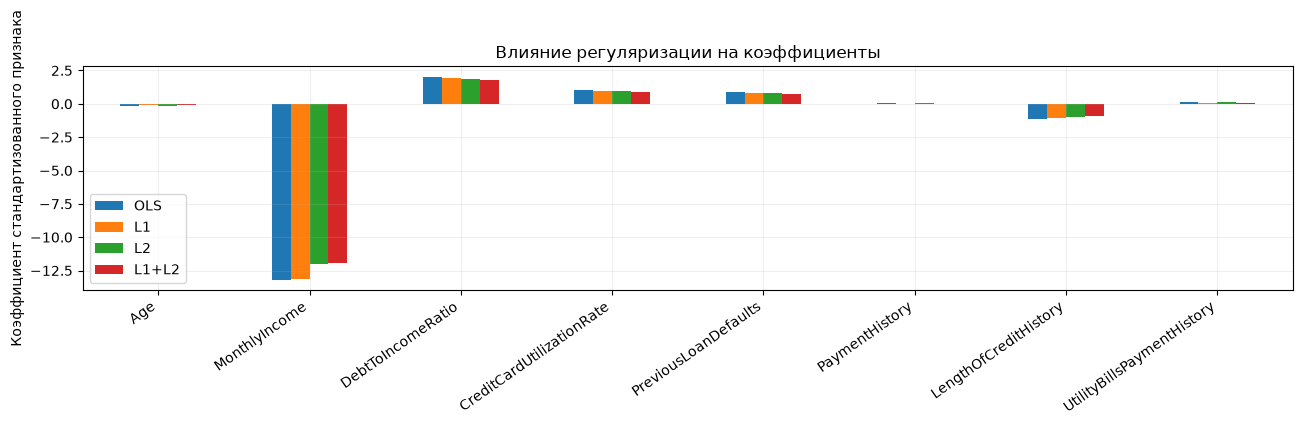

In [17]:
penalty_settings = {'L1':dict(l1=.1), 'L2':dict(l2=.1), 'L1+L2':dict(l1=.1,l2=.1)}
penalty_references = {'L1':Lasso(alpha=.1,tol=1e-12,max_iter=100000),
                      'L2':Ridge(alpha=len(A_train)*.1,solver='svd'),
                      'L1+L2':ElasticNet(alpha=.2,l1_ratio=.5,tol=1e-12,max_iter=100000)}
regularization_rows = []
regularized_models = {}
for name,setting in penalty_settings.items():
    model = RegularizedLinearRegression(**setting,tol=1e-11).fit(A_train,y_train)
    ref = penalty_references[name].fit(A_train,y_train)
    assert model.converged_
    assert np.allclose(model.coef_,ref.coef_,atol=1e-7)
    assert np.allclose(model.predict(A_val),ref.predict(A_val),atol=1e-6)
    regularized_models[name] = model
    regularization_rows.append({'Вариант':name,**metrics(y_val,model.predict(A_val)),
                                'L1_norm':np.abs(model.coef_).sum(),
                                'nonzero':int(np.count_nonzero(model.coef_)),
                                'max_coef_diff':np.max(np.abs(model.coef_-ref.coef_)),
                                'KKT':model.kkt_residual_})
display(pd.DataFrame(regularization_rows))
coefficient_table = pd.DataFrame({'OLS':ols.coef_,**{k:m.coef_ for k,m in regularized_models.items()}},index=solver_columns)
display(coefficient_table)
coefficient_table.plot.bar(figsize=(13,4),ylabel='Коэффициент стандартизованного признака',
                           title='Влияние регуляризации на коэффициенты')
plt.xticks(rotation=35,ha='right'); plt.tight_layout(); plt.show()

In [18]:
lp_rows = []
for p in [1.,1.25,1.5,1.75,2.]:
    model = RegularizedLinearRegression(lp=.05,p=p,tol=1e-10).fit(A_train,y_train)
    assert model.converged_
    assert np.all(np.diff(model.history_['objective']) <= 1e-8)
    if p in [1.,2.]:
        equivalent = RegularizedLinearRegression(**({'l1':.05} if p==1 else {'l2':.1}),tol=1e-10).fit(A_train,y_train)
        assert np.allclose(model.predict(A_val),equivalent.predict(A_val),atol=1e-8)
    lp_rows.append({'p':p,**metrics(y_val,model.predict(A_val)),
                    'iterations':model.n_iter_,'KKT':model.kkt_residual_})
display(pd.DataFrame(lp_rows))
for unsupported in [.5,0.,3.,np.nan]:
    try:
        RegularizedLinearRegression(lp=.1,p=unsupported).fit(A_train,y_train)
    except ValueError:
        pass
    else:
        raise AssertionError('Неподдерживаемый p должен отклоняться')
print('Граничные p=1,p=2, промежуточные p и недопустимые параметры проверены.')

,p,MSE,MAE,R2,MAPE,iterations,KKT
0,1.00,108.633304,8.389877,0.626852,0.196787,5,3.744163e-10
1,1.25,108.615239,8.387895,0.626914,0.196547,5,8.082951e-10
2,1.50,108.657466,8.388018,0.626769,0.196157,5,8.046238e-10
3,1.75,108.917730,8.397972,0.625875,0.195644,5,7.644713e-10
4,2.00,110.012227,8.446750,0.622115,0.195541,1,4.440892e-16


Граничные p=1,p=2, промежуточные p и недопустимые параметры проверены.


### Влияние силы регуляризации

На тех же восьми признаках сравниваю несколько значений штрафа по трём фолдам.
L1 может обнулять небольшие коэффициенты, L2 уменьшает их величины.
Слишком сильный штраф увеличивает смещение модели. В таблице MSE считается без штрафа.

In [19]:
regularization_cv = []
for kind in ['L1','L2','L1+L2','Lp1.5']:
    for strength in [.001,.1,1.]:
        values = []
        for tr,va in cv_splits:
            x = development.iloc[tr][solver_columns].to_numpy(float)
            v = development.iloc[va][solver_columns].to_numpy(float)
            s = Scaler().fit(x)
            params = {'L1':dict(l1=strength),'L2':dict(l2=strength),
                      'L1+L2':dict(l1=strength,l2=strength),
                      'Lp1.5':dict(lp=strength,p=1.5)}[kind]
            model = RegularizedLinearRegression(**params,tol=1e-8).fit(s.transform(x),development.iloc[tr].RiskScore.to_numpy())
            assert model.converged_
            values.append(mse(development.iloc[va].RiskScore.to_numpy(),model.predict(s.transform(v))))
        regularization_cv.append({'Штраф':kind,'Сила':strength,'MSE_mean':np.mean(values),
                                  'MSE_std':np.std(values,ddof=1)})
display(pd.DataFrame(regularization_cv))

,Штраф,Сила,MSE_mean,MSE_std
0,L1,0.001,114.405875,5.075228
1,L1,0.100,114.435723,5.135430
2,L1,1.000,118.840876,5.468150
3,L2,0.001,114.405432,5.074898
4,L2,0.100,115.857019,5.095279
5,L2,1.000,159.520237,4.793536
6,L1+L2,0.001,114.405516,5.075625
7,L1+L2,0.100,116.194810,5.128268
8,L1+L2,1.000,169.804854,4.422942
9,Lp1.5,0.001,114.405272,5.075527


## 9. Выбор модели для Kaggle

Все варианты сравниваются на одинаковых трёх фолдах. Нормализация, заполнение пропусков,
категории и узлы кусочно-линейных функций обучаются только внутри фолда.

В таблице `alpha` соответствует параметру Ridge. В собственной реализации используется
`λ2=alpha/n_train`. Проверяю исходные признаки, логарифмы, восстановление пропусков,
кусочно-линейные функции и их взаимодействия.
Отдельно сравниваю добавление даты и исключение годового дохода.

In [20]:
experiment_specs = [
    dict(variant='baseline',date=False,knots=5,drop_annual=False),
    dict(variant='logs',date=False,knots=5,drop_annual=False),
    dict(variant='recover',date=False,knots=5,drop_annual=False),
    dict(variant='additive',date=False,knots=5,drop_annual=False),
    dict(variant='additive',date=True,knots=5,drop_annual=False),
    dict(variant='additive',date=False,knots=15,drop_annual=False),
    dict(variant='poly',date=False,knots=5,drop_annual=False),
    dict(variant='tensor',date=False,knots=3,drop_annual=False),
    dict(variant='tensor',date=False,knots=5,drop_annual=False),
    dict(variant='tensor',date=False,knots=5,drop_annual=True),
]
experiment_rows, experiment_details = [], {}
for number,spec in enumerate(experiment_specs):
    for alpha in ([0.,1.,100.] if spec['variant']=='baseline' else [1.,10.,100.]):
        factory = (lambda n:LinearRegressionOwn()) if alpha==0 else (
            lambda n,a=alpha:RegularizedLinearRegression(l2=a/n))
        folds,oof = cross_validate_own(development,lambda s=spec:FeatureBuilder(**s),factory,cv_splits)
        name = f"{spec['variant']}; knots={spec['knots']}; date={spec['date']}; drop_annual={spec['drop_annual']}; alpha={alpha:g}"
        experiment_rows.append({'Вариант':name,**spec,'alpha':alpha,'features':int(folds.features.max()),
                                'MSE_mean':folds.MSE.mean(),'MSE_std':folds.MSE.std(),
                                **metrics(development.RiskScore.to_numpy(),oof)})
        experiment_details[name] = dict(spec=spec.copy(),alpha=alpha,folds=folds,oof=oof)
experiments = pd.DataFrame(experiment_rows).sort_values('MSE_mean').reset_index(drop=True)
display(experiments[['variant','knots','date','drop_annual','alpha','features',
                     'MSE','MSE_std','MAE','R2','MAPE']])
best_name = experiments.iloc[0]['Вариант']
best = experiment_details[best_name]
FINAL_FEATURES = best['spec'].copy()
FINAL_ALPHA = float(best['alpha'])
display(best['folds'])
print('Фиксируем признаки:',FINAL_FEATURES,'; alpha:',FINAL_ALPHA)
print('Development OOF:',metrics(development.RiskScore.to_numpy(),best['oof']))

,variant,knots,date,drop_annual,alpha,features,MSE,MSE_std,MAE,R2,MAPE
0,tensor,5,False,False,100.0,1092,25.276609,0.920118,3.714711,0.914504,0.085908
1,tensor,5,False,True,100.0,1085,25.299077,0.889329,3.716609,0.914428,0.085944
2,tensor,3,False,False,1.0,394,25.583052,1.041164,3.745275,0.913468,0.086397
3,tensor,5,False,False,10.0,1092,25.592059,0.947563,3.728777,0.913437,0.086407
4,tensor,5,False,True,10.0,1085,25.603003,0.908706,3.728837,0.913400,0.086405
5,tensor,3,False,False,10.0,394,26.006704,1.034844,3.781106,0.912035,0.087062
6,tensor,5,False,False,1.0,1092,26.364408,0.911499,3.784704,0.910825,0.087803
7,tensor,5,False,True,1.0,1085,26.366543,0.875745,3.785112,0.910817,0.087824
8,poly,5,False,False,1.0,252,26.879729,1.069110,3.909968,0.909082,0.090635
9,tensor,3,False,False,100.0,394,27.241649,1.367261,3.885093,0.907857,0.089402


,fold,n_train,n_val,features,MSE,MAE,R2,MAPE
0,1,5220,2610,1092,24.257942,3.677156,0.916676,0.084429
1,2,5220,2610,1092,26.047391,3.748250,0.912872,0.086867
2,3,5220,2610,1092,25.524495,3.718725,0.914016,0.086427


Фиксируем признаки: {'variant': 'tensor', 'date': False, 'knots': 5, 'drop_annual': False} ; alpha: 100.0
Development OOF: {'MSE': 25.276609113248405, 'MAE': 3.7147105602933594, 'R2': 0.9145040437143572, 'MAPE': 0.0859076161968384}


### Результаты сравнения

- Логарифмы снизили CV MSE примерно с 54 до 40.
- Кусочно-линейные функции снизили ошибку примерно до 28.
- Их попарные произведения с L2 дали лучший результат — MSE 25,2766.
- Для этого набора `alpha=100` оказался лучше 1 и 10.
- Добавление даты и исключение годового дохода не улучшили результат.
- Увеличение числа узлов до 15 в аддитивной модели также не дало выигрыша.

Выбираю вариант `tensor` с пятью узлами и `alpha=100`.

### Дополнительные эксперименты

Также проверены полиномы, пороговые сочетания, финансовые отношения и радиальные функции.
Они не улучшили выбранный вариант. Ниже записаны результаты этих отдельных запусков;
основное сравнение выше пересчитывается при выполнении ноутбука.

Минимум CV использовался при подборе, поэтому далее нужна проверка на отложенной части.
MSE < 18 среди проверенных вариантов не получена.

In [21]:
display(pd.DataFrame([
    ['Широкий квадратичный базис',31.2043],
    ['Полином третьей степени',26.7086],
    ['Полином четвёртой степени',28.0213],
    ['Полином пятой степени',31.8017],
    ['Попарные фиксированные пороги',26.1432],
    ['Финансовые отношения и проекции',25.6395],
    ['1000 явных радиальных функций',25.6110],
],columns=['Дополнительная поисковая ветвь','Лучший development CV MSE (архив)']))

,Дополнительная поисковая ветвь,Лучший development CV MSE (архив)
0,Широкий квадратичный базис,31.2043
1,Полином третьей степени,26.7086
2,Полином четвёртой степени,28.0213
3,Полином пятой степени,31.8017
4,Попарные фиксированные пороги,26.1432
5,Финансовые отношения и проекции,25.6395
6,1000 явных радиальных функций,25.6110


## 10. Проверка на отложенной выборке

Проверяю выбранный вариант на 1 958 строках, которые не использовались при подборе.
Настройки модели после этой проверки не меняю.
Локальная оценка может отличаться от результата на Kaggle.

,MSE,MAE,R2,MAPE
"Отложенная часть, выбранная модель",23.202838,3.543714,0.923179,0.080914


max |своя финальная модель - sklearn|: 8.597567102697212e-13


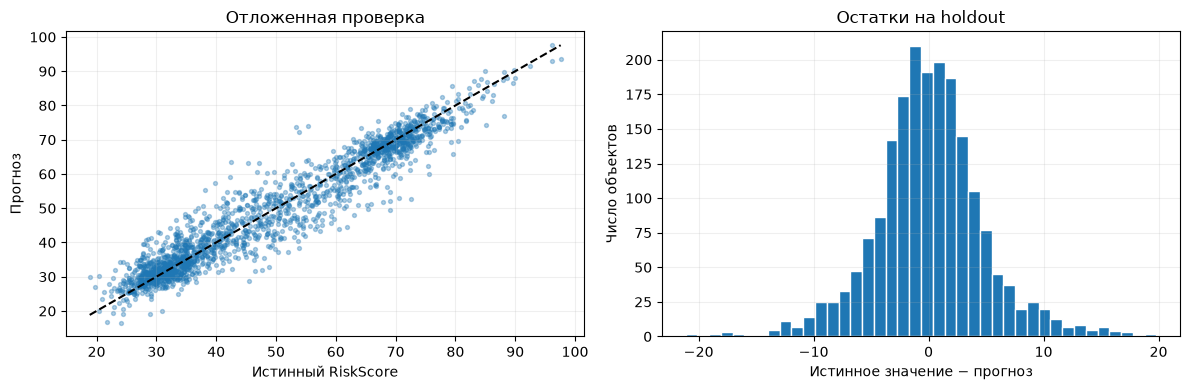

In [22]:
holdout = clean.iloc[holdout_indices].reset_index(drop=True)
chosen_transformer = FeatureBuilder(**FINAL_FEATURES).fit(development)
chosen_x = chosen_transformer.transform(development)
chosen_val = chosen_transformer.transform(holdout)
chosen_model = (LinearRegressionOwn() if FINAL_ALPHA==0 else
                RegularizedLinearRegression(l2=FINAL_ALPHA/len(development)))
chosen_model.fit(chosen_x,development.RiskScore.to_numpy())
holdout_predictions = chosen_model.predict(chosen_val)
holdout_metrics = metrics(holdout.RiskScore.to_numpy(),holdout_predictions)
display(pd.DataFrame([holdout_metrics],index=['Отложенная часть, выбранная модель']))
if FINAL_ALPHA:
    chosen_reference = Ridge(alpha=FINAL_ALPHA,solver='cholesky').fit(chosen_x,development.RiskScore)
else:
    chosen_reference = LinearRegression().fit(chosen_x,development.RiskScore)
max_final_difference = np.max(np.abs(holdout_predictions-chosen_reference.predict(chosen_val)))
assert np.allclose(holdout_predictions,chosen_reference.predict(chosen_val),atol=1e-6)
print('max |своя финальная модель - sklearn|:',max_final_difference)
fig,axes = plt.subplots(1,2,figsize=(12,4))
axes[0].scatter(holdout.RiskScore,holdout_predictions,s=8,alpha=.35)
lo,hi = holdout.RiskScore.min(),holdout.RiskScore.max()
axes[0].plot([lo,hi],[lo,hi],'k--')
axes[0].set(xlabel='Истинный RiskScore',ylabel='Прогноз',title='Отложенная проверка')
axes[1].hist(holdout.RiskScore-holdout_predictions,bins=40,edgecolor='white')
axes[1].set(xlabel='Истинное значение − прогноз',ylabel='Число объектов',title='Остатки на holdout')
fig.tight_layout();plt.show()

## 11. Leave-one-out

Для каждого объекта модель обучается на всех остальных строках.
LOO выполняется на всей очищенной выборке из 9 788 наблюдений.
Чтобы сократить время, использую фиксированные восемь признаков из раздела 5
и аналитическое решение. Это оценка простой модели, а не итогового варианта `tensor`.

В каждом разбиении заново обучаются скейлер и регрессия.
Все метрики считаются по общему вектору предсказаний вне обучения.
R² по одноэлементным фолдам не усредняется.

На 64 строках дополнительно сверяю разбиения и предсказания со sklearn.
LOO выполняется после выбора итоговой модели и не используется для её настройки.

In [23]:
def loo_predict_own(x,y):
    oof = np.full(len(y),np.nan)
    visits = np.zeros(len(y),dtype=int)
    for tr,va in loo_splits(len(y)):
        s = Scaler().fit(x[tr])
        m = LinearRegressionOwn().fit(s.transform(x[tr]),y[tr])
        oof[va] = m.predict(s.transform(x[va]))
        visits[va] += 1
    assert np.all(visits==1) and np.isfinite(oof).all()
    return oof

loo_x = clean[solver_columns].to_numpy(float)
loo_y = clean.RiskScore.to_numpy()
assert np.isfinite(loo_x).all()
start_loo = time.perf_counter()
loo_oof = loo_predict_own(loo_x,loo_y)
loo_seconds = time.perf_counter()-start_loo
loo_metrics = metrics(loo_y,loo_oof)
display(pd.DataFrame([{'n':len(loo_y),'seconds':loo_seconds,**loo_metrics}],
                     index=['Полный собственный LOO: простая модель']))
small_n = 64
small_own = loo_predict_own(loo_x[:small_n],loo_y[:small_n])
small_ref = np.full(small_n,np.nan)
for (tr,va),(tr_ref,va_ref) in zip(loo_splits(small_n),LeaveOneOut().split(loo_x[:small_n])):
    assert np.array_equal(tr,tr_ref) and np.array_equal(va,va_ref)
    s = StandardScaler().fit(loo_x[tr_ref])
    small_ref[va_ref] = LinearRegression().fit(s.transform(loo_x[tr_ref]),loo_y[tr_ref]).predict(s.transform(loo_x[va_ref]))
assert np.allclose(small_own,small_ref,atol=1e-8)
print('max |LOO own - sklearn| на проверочных 64 строках:',np.max(np.abs(small_own-small_ref)))

,n,seconds,MSE,MAE,R2,MAPE
Полный собственный LOO: простая модель,9788,29.799665,114.456828,8.587007,0.614583,0.201862


max |LOO own - sklearn| на проверочных 64 строках: 4.263256414560601e-14


## 12. Финальное обучение и файл посылки

Обучаю выбранную модель на всех 9 788 строках после очистки и получаю прогноз для `test.csv`.
Тестовые данные не участвуют в обучении преобразований.
Предсказания сохраняю без округления и ограничения диапазона.

Проверяю столбцы `ID,RiskScore`, порядок идентификаторов, число строк и отсутствие пропусков.
`ID` берётся из тестового файла.

In [24]:
final_transformer = FeatureBuilder(**FINAL_FEATURES).fit(clean)
final_x = final_transformer.transform(clean)
test_x = final_transformer.transform(test)
final_model = (LinearRegressionOwn() if FINAL_ALPHA==0 else
               RegularizedLinearRegression(l2=FINAL_ALPHA/len(clean)))
final_model.fit(final_x,clean.RiskScore.to_numpy())
test_predictions = final_model.predict(test_x)
assert np.isfinite(test_predictions).all() and len(test_predictions)==len(test)
submission = pd.DataFrame({'ID':test.ID.copy(),'RiskScore':test_predictions})
assert submission.columns.tolist()==example.columns.tolist()==['ID','RiskScore']
assert submission.ID.equals(test.ID) and submission.ID.equals(example.ID)
assert len(submission)==len(test)==len(example)
assert pd.api.types.is_numeric_dtype(submission.RiskScore)
assert not submission.isna().any().any()
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
submission_path = OUTPUT_DIR/'submission.csv'
submission.to_csv(submission_path,index=False)
saved = pd.read_csv(submission_path)
assert saved.columns.tolist()==['ID','RiskScore'] and saved.ID.equals(test.ID)
assert len(saved)==len(test) and np.isfinite(saved.RiskScore).all()
assert np.allclose(saved.RiskScore,test_predictions,rtol=1e-14,atol=1e-12)
display(saved.head())
print('Сохранено:',submission_path.resolve(),'; строк:',len(saved))
print('Диапазон предсказаний:',saved.RiskScore.min(),saved.RiskScore.max())

,ID,RiskScore
0,0,33.104570
1,1,52.521809
2,2,30.773637
3,3,34.370089
4,4,32.771915


Сохранено: C:\MachineLearning\lab1_regression\submission.csv ; строк: 5000
Диапазон предсказаний: 18.273375219311454 96.78592248416018


## 13. Итоги

После очистки данных и сравнения вариантов лучшей оказалась линейная регрессия с L2
на попарных произведениях кусочно-линейных функций признаков.

- Development CV MSE: **25,2766**.
- MSE на отложенной части: **23,2028**.
- MAE: **3,5437**, R²: **0,9232**, MAPE: **8,0914%**.

Цель MSE < 18 локально не достигнута. Оценка Kaggle будет известна после отправки `submission.csv`.

Аналитическое решение, GD, метрики и нормализации совпали с реализациями sklearn
с точностью до численных погрешностей. SGD дал сопоставимое качество.
Для L1, L2 и L1+L2 проверено совпадение коэффициентов с Lasso, Ridge и ElasticNet.
Lp проверена при нескольких значениях p, включая соответствие L1 и L2 на границах.

### Выполненные пункты

| Пункт | Раздел |
|---|---|
| EDA, графики и выводы | 1–2 |
| z-score и min-max | 4 |
| Аналитическое решение, GD, SGD | 5 |
| k-fold и leave-one-out | 7, 11 |
| MSE, MAE, R², MAPE: формулы, проверки, сравнения | 3 |
| Дополнительно: L1, L2, L1+L2 | 8 |
| Дополнительно: Lp с параметром p | 8 |
| Сравнение вариантов и отложенная проверка | 9–10 |
| Финальное обучение и submission.csv | 12 |

In [25]:
summary = pd.DataFrame([
    {'Оценка':'Development CV: выбор модели',**metrics(development.RiskScore.to_numpy(),best['oof'])},
    {'Оценка':'Независимый holdout',**holdout_metrics},
    {'Оценка':'Полный LOO: фиксированная простая модель',**loo_metrics}])
display(summary)
display(Markdown(f"**Выбранный вариант:** `{best_name}`. "
                 f"**Holdout MSE:** {holdout_metrics['MSE']:.6f}; "
                 f"**MAPE:** {100*holdout_metrics['MAPE']:.3f}%. "
                 f"Локальная цель MSE < 18 {'достигнута' if holdout_metrics['MSE']<18 else 'не достигнута'}. "
                 'Фактическая оценка Kaggle отсутствует.'))
print('Все встроенные проверки и создание submission.csv завершены.')

,Оценка,MSE,MAE,R2,MAPE
0,Development CV: выбор модели,25.276609,3.714711,0.914504,0.085908
1,Независимый holdout,23.202838,3.543714,0.923179,0.080914
2,Полный LOO: фиксированная простая модель,114.456828,8.587007,0.614583,0.201862


**Выбранный вариант:** `tensor; knots=5; date=False; drop_annual=False; alpha=100`. **Holdout MSE:** 23.202838; **MAPE:** 8.091%. Локальная цель MSE < 18 не достигнута. Фактическая оценка Kaggle отсутствует.

Все встроенные проверки и создание submission.csv завершены.
